# A model without climate data

The age-period model from the previous notebook, fitted on all the training deaths. It uses only age, sex and the date of death, so its curves show directly which deaths the label calls climate-sensitive, and it writes a submission in the challenge format.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from climate_health.data import DEMOGRAPHIC, START, TARGET, load
from climate_health.models import age_period
from climate_health.plots import AQUA, BLUE, GREY, ORANGE, VIOLET, YELLOW
from climate_health.validation import cross_val_predict, summarize

train, test = load()
y = train[TARGET].values
summarize(cross_val_predict(age_period, train[DEMOGRAPHIC], y, train.site), y).round(4)

,score,F1,AUC
mean,0.8192,0.8150,0.8254
std,0.0004,0.0008,0.0008


Cross-validation holds out whole sites and is repeated 10 times, as in the previous notebook.

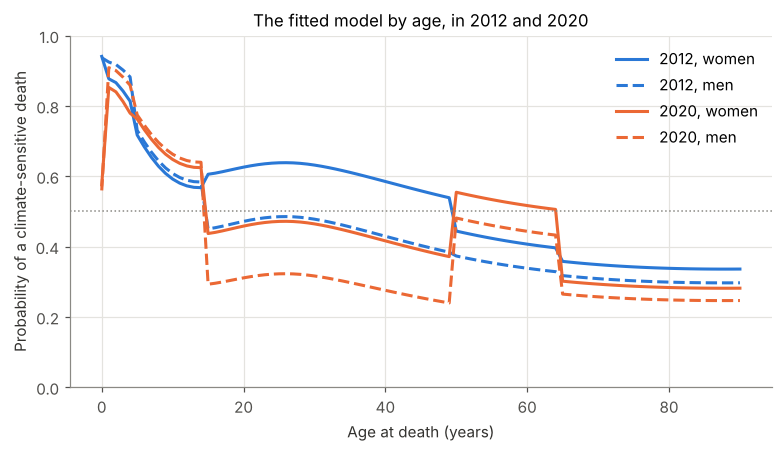

In [2]:
model = age_period().fit(train[DEMOGRAPHIC].values, y)


def predict(age, male, date):
    years = (pd.Timestamp(date) - START).days / 365.25
    age = np.atleast_1d(age).astype(float)
    rows = np.column_stack([age, np.full_like(age, male), np.full_like(age, years)])
    return model.predict_proba(rows)[:, 1]


ages = np.arange(0, 91)
fig, ax = plt.subplots(figsize=(7, 4))
for date, color in [("2012-07-01", BLUE), ("2020-07-01", ORANGE)]:
    for male, style, sex in [(0, "-", "women"), (1, "--", "men")]:
        ax.plot(ages, predict(ages, male, date), color=color, linestyle=style, linewidth=2,
                label=f"{date[:4]}, {sex}")
ax.axhline(0.5, color=GREY, linewidth=1, linestyle=":")
ax.set_xlabel("Age at death (years)")
ax.set_ylabel("Probability of a climate-sensitive death")
ax.set_ylim(0, 1)
ax.set_title("The fitted model by age, in 2012 and 2020")
ax.legend(loc="upper right")
fig.savefig("images/model_by_age.png")
plt.show()

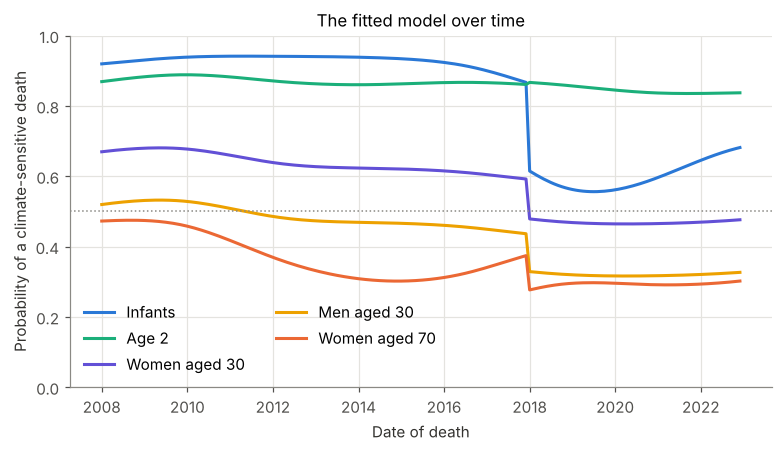

In [3]:
dates = pd.date_range("2008-01-01", "2022-12-31", freq="MS")
fig, ax = plt.subplots(figsize=(7, 4))
for age, male, label, color in [(0, 0, "Infants", BLUE), (2, 0, "Age 2", AQUA), (30, 0, "Women aged 30", VIOLET),
                                (30, 1, "Men aged 30", YELLOW), (70, 0, "Women aged 70", ORANGE)]:
    ax.plot(dates, [predict(age, male, d)[0] for d in dates], color=color, linewidth=2, label=label)
ax.axhline(0.5, color=GREY, linewidth=1, linestyle=":")
ax.set_xlabel("Date of death")
ax.set_ylabel("Probability of a climate-sensitive death")
ax.set_ylim(0, 1)
ax.set_title("The fitted model over time")
ax.legend(loc="lower left", ncol=2)
fig.savefig("images/model_by_date.png")
plt.show()

The model scores 0.8192 in cross-validation that holds out whole sites, the best of every model and feature set in the previous notebook, without any climate variable. Its curves restate what the label tracks. By age, the probability is highest for young children, drops at adolescence and is lowest in old age, with women above men between 15 and 50; the steps at 1, 5, 15, 50 and 65 years come from the age groups that carry the model's time and sex effects. Over time, the infant curve falls by about 25 points at the start of 2018, more than any other group, which is the 2017–2018 change of the first notebook.

## Submission

`TargetRAUC` is the predicted probability and `TargetF1` its 0.5 cut, in the order of `SampleSubmission.csv`.

In [4]:
order = pd.read_csv("data/SampleSubmission.csv")[["ID"]]
probability = model.predict_proba(test[DEMOGRAPHIC].values)[:, 1]
submission = order.merge(pd.DataFrame({"ID": test.ID, "TargetF1": (probability >= 0.5).astype(int),
                                       "TargetRAUC": probability}), on="ID", how="left")
assert len(submission) == len(order) and submission.notna().all().all()
submission.to_csv("submission.csv", index=False)
print(f"{len(submission)} rows, {submission.TargetF1.mean():.1%} predicted climate-sensitive")
submission.head()

1030 rows, 68.9% predicted climate-sensitive


,ID,TargetF1,TargetRAUC
0,ID_E760D84B,0,0.464905
1,ID_6EDEA907,1,0.558558
2,ID_B9FFC8D8,0,0.465463
3,ID_74C6C94E,0,0.460124
4,ID_0E02825D,1,0.684083
